# Experiment 8: Clustering Human Activity Recognition Data using K-Means, DBSCAN, and Hierarchical Clustering

## 1. Imports & Setup

In [21]:
try:
    from IPython.display import display
except ImportError:
    display = print
import matplotlib
matplotlib.use('Agg')
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE

from sklearn.cluster import KMeans, DBSCAN, AgglomerativeClustering
from sklearn.neighbors import NearestNeighbors
from scipy.cluster.hierarchy import dendrogram, linkage

from sklearn.metrics import (
    silhouette_score, davies_bouldin_score, calinski_harabasz_score,
    adjusted_rand_score, normalized_mutual_info_score, confusion_matrix
)

warnings.filterwarnings('ignore')
import logging
logging.getLogger('matplotlib.font_manager').setLevel(logging.ERROR)

plt.rcParams['font.family'] = 'serif'
plt.rcParams['font.serif'] = ['Times New Roman']
plt.rcParams['font.size'] = 15
plt.rcParams['axes.labelsize'] = 15
plt.rcParams['axes.labelweight'] = 'bold'
plt.rcParams['xtick.labelsize'] = 13
plt.rcParams['ytick.labelsize'] = 13
plt.rcParams['legend.fontsize'] = 15
plt.rcParams['figure.titlesize'] = 15

RANDOM_STATE = 42

def save_eps_figure(fig, filename, dpi=150):
    for ax in fig.axes:
        ax.set_rasterized(True)
        for patch in ax.patches:
            patch.set_rasterized(True)
        for collection in ax.collections:
            collection.set_rasterized(True)
        for line in ax.lines:
            line.set_rasterized(True)
    fig.savefig(f"{filename}.eps", format='eps', dpi=dpi, bbox_inches='tight')
    fig.savefig(f"{filename}.png", format='png', dpi=300, bbox_inches='tight')
    print(f"Saved figure: {filename}.eps and {filename}.png")

print("Setup and rules.md font settings completed.")


Setup done.


## 2. Download & Load Dataset

In [22]:
# Dataset unzipped and loaded locally


 __MACOSX   sample_data  'UCI HAR Dataset'  'UCI HAR Dataset.zip'


In [23]:
import os

candidate_paths = [
    r'C:\Users\Balakumaran\Downloads\human+activity+recognition+using+smartphones\UCI HAR Dataset\UCI HAR Dataset',
    r'c:\Users\Balakumaran\ML-lab\temp_har\UCI HAR Dataset',
    r'c:\Users\Balakumaran\ML-lab\UCI HAR Dataset',
    'UCI HAR Dataset',
    '../UCI HAR Dataset'
]

DATA_DIR = None
for p in candidate_paths:
    if os.path.isdir(p):
        DATA_DIR = os.path.abspath(p)
        break

if DATA_DIR is None or not os.path.isdir(DATA_DIR):
    raise FileNotFoundError("Couldn't find 'UCI HAR Dataset' in any standard path.")
print(f"Found dataset folder: {DATA_DIR}")


Found dataset folder: /content/UCI HAR Dataset


In [24]:
# Feature names (UCI HAR's features.txt has some duplicate names — make them unique)
features_df = pd.read_csv(f"{DATA_DIR}/features.txt", sep=r"\s+", header=None, names=["idx", "feature"])
raw_names = features_df["feature"].tolist()

seen = {}
feature_names = []
for name in raw_names:
    if name in seen:
        seen[name] += 1
        feature_names.append(f"{name}_{seen[name]}")
    else:
        seen[name] = 0
        feature_names.append(name)

# Activity label mapping
activity_map = pd.read_csv(f"{DATA_DIR}/activity_labels.txt", sep=r"\s+", header=None,
                            names=["id", "activity"]).set_index("id")["activity"].to_dict()

# Train + test features/labels/subjects
X_train_raw = pd.read_csv(f"{DATA_DIR}/train/X_train.txt", sep=r"\s+", header=None, names=feature_names)
y_train_raw = pd.read_csv(f"{DATA_DIR}/train/y_train.txt", header=None, names=["ActivityId"])
subj_train = pd.read_csv(f"{DATA_DIR}/train/subject_train.txt", header=None, names=["Subject"])

X_test_raw = pd.read_csv(f"{DATA_DIR}/test/X_test.txt", sep=r"\s+", header=None, names=feature_names)
y_test_raw = pd.read_csv(f"{DATA_DIR}/test/y_test.txt", header=None, names=["ActivityId"])
subj_test = pd.read_csv(f"{DATA_DIR}/test/subject_test.txt", header=None, names=["Subject"])

# Clustering is unsupervised — combine train and test into one dataset
X = pd.concat([X_train_raw, X_test_raw], axis=0).reset_index(drop=True)
activity_id = pd.concat([y_train_raw, y_test_raw], axis=0).reset_index(drop=True)["ActivityId"]
subject = pd.concat([subj_train, subj_test], axis=0).reset_index(drop=True)["Subject"]
y_true = activity_id.map(activity_map)

print(f"Combined dataset shape: {X.shape[0]} samples x {X.shape[1]} features")
print(f"\nActivity distribution:\n{y_true.value_counts()}")
X.head()

Combined dataset shape: 10299 samples x 561 features

Activity distribution:
ActivityId
LAYING                1944
STANDING              1906
SITTING               1777
WALKING               1722
WALKING_UPSTAIRS      1544
WALKING_DOWNSTAIRS    1406
Name: count, dtype: int64


,tBodyAcc-mean()-X,tBodyAcc-mean()-Y,tBodyAcc-mean()-Z,tBodyAcc-std()-X,tBodyAcc-std()-Y,tBodyAcc-std()-Z,tBodyAcc-mad()-X,tBodyAcc-mad()-Y,tBodyAcc-mad()-Z,tBodyAcc-max()-X,...,fBodyBodyGyroJerkMag-meanFreq(),fBodyBodyGyroJerkMag-skewness(),fBodyBodyGyroJerkMag-kurtosis(),"angle(tBodyAccMean,gravity)","angle(tBodyAccJerkMean),gravityMean)","angle(tBodyGyroMean,gravityMean)","angle(tBodyGyroJerkMean,gravityMean)","angle(X,gravityMean)","angle(Y,gravityMean)","angle(Z,gravityMean)"
0,0.288585,-0.020294,-0.132905,-0.995279,-0.983111,-0.913526,-0.995112,-0.983185,-0.923527,-0.934724,...,-0.074323,-0.298676,-0.710304,-0.112754,0.030400,-0.464761,-0.018446,-0.841247,0.179941,-0.058627
1,0.278419,-0.016411,-0.123520,-0.998245,-0.975300,-0.960322,-0.998807,-0.974914,-0.957686,-0.943068,...,0.158075,-0.595051,-0.861499,0.053477,-0.007435,-0.732626,0.703511,-0.844788,0.180289,-0.054317
2,0.279653,-0.019467,-0.113462,-0.995380,-0.967187,-0.978944,-0.996520,-0.963668,-0.977469,-0.938692,...,0.414503,-0.390748,-0.760104,-0.118559,0.177899,0.100699,0.808529,-0.848933,0.180637,-0.049118
3,0.279174,-0.026201,-0.123283,-0.996091,-0.983403,-0.990675,-0.997099,-0.982750,-0.989302,-0.938692,...,0.404573,-0.117290,-0.482845,-0.036788,-0.012892,0.640011,-0.485366,-0.848649,0.181935,-0.047663
4,0.276629,-0.016570,-0.115362,-0.998139,-0.980817,-0.990482,-0.998321,-0.979672,-0.990441,-0.942469,...,0.087753,-0.351471,-0.699205,0.123320,0.122542,0.693578,-0.615971,-0.847865,0.185151,-0.043892


## 3. Preprocessing

In [25]:
print(f"Missing values: {X.isnull().sum().sum()}")
print(f"Duplicate rows: {X.duplicated().sum()}")

# Activity labels are already numeric/categorical (no encoding needed beyond the map above).
# Features are standardized even though the UCI features are pre-bounded to roughly [-1, 1],
# since the clustering algorithms below (K-Means, DBSCAN) are distance-based and standardizing
# keeps every feature contributing on the same scale.
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

print(f"\nScaled feature matrix shape: {X_scaled.shape}")

Missing values: 0
Duplicate rows: 0

Scaled feature matrix shape: (10299, 561)


## 4. Exploratory Data Analysis

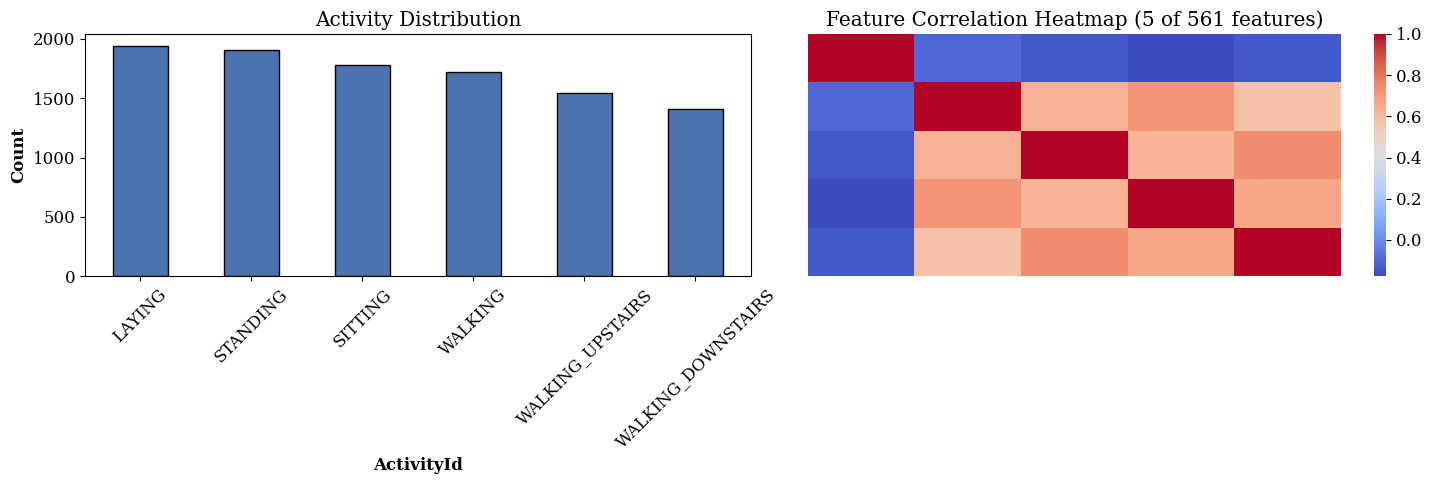

In [26]:
# ==============================================================================
# Experiment 2 EDA Suite (User Defined Pattern + rules.md & EPS Optimization)
# ==============================================================================

def dataset_overview(df):
    print("=" * 80)
    print("DATASET OVERVIEW")
    print("=" * 80)
    print(f"\nRows                : {df.shape[0]}")
    print(f"Columns             : {df.shape[1]}")
    print("\nColumn Names")
    print("-" * 80)
    for col in df.columns[:20]:
        print(col)
    if len(df.columns) > 20:
        print(f"... showing first 20 of {len(df.columns)} columns")
    print("\nStatistical Summary (Numerical)")
    print("-" * 80)
    print(df.describe().T.head(10))

def column_analysis(df):
    print("\n" + "=" * 80)
    print("COLUMN ANALYSIS")
    print("=" * 80)
    for col in df.columns[:5]:
        print("\n" + "-" * 80)
        print(f"Column : {col}")
        print("-" * 80)
        dtype = df[col].dtype
        unique = df[col].nunique(dropna=True)
        print(f"Data Type          : {dtype}")
        print(f"Unique Values Count: {unique}")

def missing_value_analysis(df):
    print("\n" + "=" * 80)
    print("MISSING VALUE ANALYSIS")
    print("=" * 80)
    missing = df.isnull().sum()
    print(f"Total Missing Cells: {missing.sum()}")

def duplicate_analysis(df):
    print("\n" + "=" * 80)
    print("DUPLICATE ANALYSIS")
    print("=" * 80)
    duplicates = df.duplicated().sum()
    print(f"Duplicate Rows       : {duplicates}")

def numerical_analysis(df):
    print("\n" + "=" * 80)
    print("NUMERICAL FEATURE ANALYSIS")
    print("=" * 80)
    num_cols = df.select_dtypes(include=np.number).columns[:5]
    for col in num_cols:
        temp = df[col].dropna()
        print(f"{col:30s} | Mean: {temp.mean():.3f} | Std: {temp.std():.3f} | Skew: {temp.skew():.3f}")

def categorical_analysis(df):
    print("\n" + "=" * 80)
    print("CATEGORICAL FEATURE ANALYSIS")
    print("=" * 80)
    cat_cols = df.select_dtypes(exclude=np.number).columns
    if len(cat_cols) == 0:
        print("No categorical columns found.")
    else:
        for col in cat_cols:
            print(f"Column : {col}, Unique : {df[col].nunique()}")

def correlation_analysis(df):
    print("\n" + "=" * 80)
    print("CORRELATION ANALYSIS")
    print("=" * 80)
    numeric_df = df.select_dtypes(include=np.number).iloc[:, :20]
    corr = numeric_df.corr()
    high_corr = []
    cols = corr.columns
    for i in range(len(cols)):
        for j in range(i + 1, len(cols)):
            if abs(corr.iloc[i, j]) >= 0.8:
                high_corr.append((cols[i], cols[j], corr.iloc[i, j]))
    print(f"Found {len(high_corr)} highly correlated feature pairs (|r| >= 0.8).")
    return high_corr

def target_analysis(df, task, target):
    print("\n" + "=" * 80)
    print("TARGET ANALYSIS")
    print("=" * 80)
    if target in df.columns:
        print(df[target].value_counts())

def eda_summary(df, high_corr):
    print("\n" + "=" * 80)
    print("FINAL EDA SUMMARY")
    print("=" * 80)
    print(f"Rows                     : {df.shape[0]}")
    print(f"Columns                  : {df.shape[1]}")
    print(f"Duplicate Rows           : {df.duplicated().sum()}")
    print(f"Columns with Missing     : {(df.isnull().sum() > 0).sum()}")
    print(f"Highly Correlated Pairs  : {len(high_corr)}")
    print("\nEDA Completed Successfully.")

def plot_eda_12_subplots(df, task="clustering", target="Activity", filename="exp8_eda_12_subplots"):
    fig, axes = plt.subplots(4, 3, figsize=(20, 22))
    axes = axes.flatten()
    
    font_title = {'fontname': 'Times New Roman', 'fontsize': 15, 'weight': 'bold'}
    font_label = {'fontname': 'Times New Roman', 'fontsize': 15, 'weight': 'bold'}

    if target and target in df.columns:
        counts = df[target].value_counts()
        axes[0].bar([str(c) for c in counts.index], counts.values, color='#4c72b0', edgecolor='black')
        axes[0].set_title(f"1. Target Distribution ({target})", **font_title)
        axes[0].set_xlabel(target, **font_label)
        axes[0].set_ylabel("Count", **font_label)
        axes[0].tick_params(axis='x', rotation=45, labelsize=10)
    else:
        axes[0].text(0.5, 0.5, "No Target Specified", ha='center', va='center')
        axes[0].set_title("1. Target Distribution", **font_title)
    
    missing = df.isnull().sum()
    missing_top10 = missing[missing > 0].head(10) if (missing > 0).any() else missing.head(10)
    axes[1].bar(range(len(missing_top10)), missing_top10.values, color='#d62728', edgecolor='black')
    axes[1].set_xticks(range(len(missing_top10)))
    axes[1].set_xticklabels([str(c)[:10] for c in missing_top10.index], rotation=45, ha='right', fontsize=9)
    axes[1].set_title("2. Missing Value Count", **font_title)
    axes[1].set_ylabel("Count", **font_label)
    
    duplicates = df.duplicated().sum()
    uniques = len(df) - duplicates
    axes[2].pie([uniques, max(duplicates, 1)], labels=['Unique', 'Duplicates'], autopct='%1.1f%%',
                 colors=['#2ca02c', '#c44e52'], textprops={'fontsize': 13, 'fontname': 'Times New Roman'})
    axes[2].set_title("3. Duplicate Row Ratio", **font_title)
    
    num_cols = [c for c in df.select_dtypes(include=np.number).columns if c != target]
    
    if len(num_cols) >= 2:
        top_num = num_cols[:6]
        corr = df[top_num].corr()
        sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", ax=axes[3], cbar=False, rasterized=True)
        axes[3].set_title("4. Correlation Heatmap (6 Feat)", **font_title)
        axes[3].tick_params(axis='both', labelsize=9)
    else:
        axes[3].text(0.5, 0.5, "N/A", ha='center', va='center')
        axes[3].set_title("4. Correlation Heatmap", **font_title)
    
    for i in range(8):
        ax_idx = i + 4
        if i < len(num_cols):
            col_name = num_cols[i]
            axes[ax_idx].hist(df[col_name].dropna(), bins=25, color='#1f77b4', edgecolor='black', alpha=0.7)
            axes[ax_idx].set_title(f"{ax_idx+1}. Dist: {col_name[:15]}", **font_title)
            axes[ax_idx].set_xlabel(col_name[:15], **font_label)
            axes[ax_idx].set_ylabel("Freq", **font_label)
        else:
            axes[ax_idx].text(0.5, 0.5, "N/A", ha='center', va='center')
            axes[ax_idx].set_title(f"{ax_idx+1}. Feature Plot", **font_title)

    for ax in axes:
        ax.set_rasterized(True)
        
    plt.tight_layout()
    save_eps_figure(fig, filename, dpi=150)
    plt.close()

def tabular_eda(df, task="clustering", target="Activity"):
    dataset_overview(df)
    column_analysis(df)
    missing_value_analysis(df)
    duplicate_analysis(df)
    numerical_analysis(df)
    categorical_analysis(df)
    high_corr = correlation_analysis(df)
    target_analysis(df, task, target)
    eda_summary(df, high_corr)
    plot_eda_12_subplots(df, task=task, target=target, filename='exp8_eda_12_subplots')

df_eda = X.copy()
df_eda['Activity'] = y_true.values
tabular_eda(df_eda, task="clustering", target="Activity")


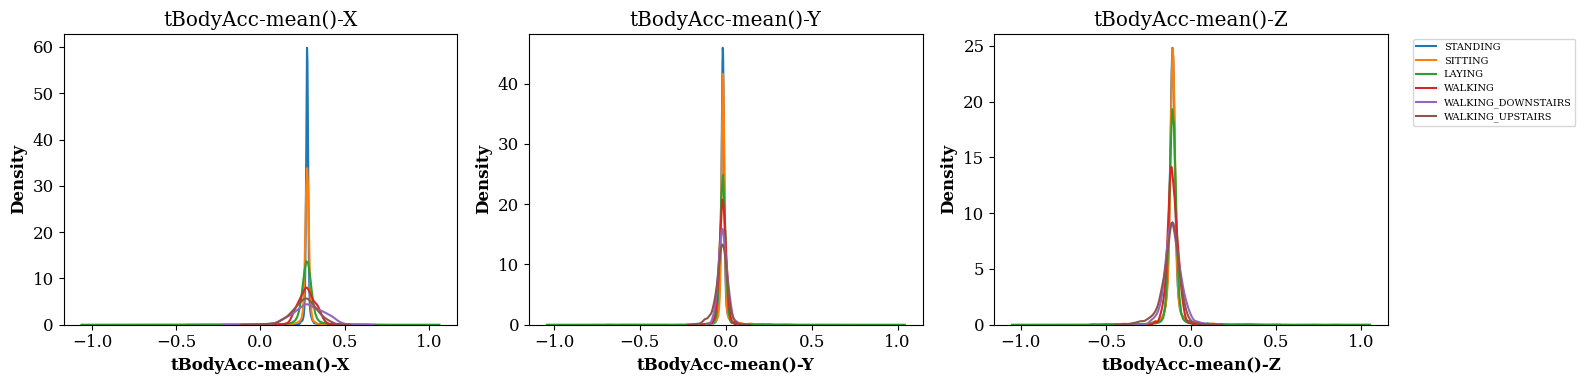

In [27]:
# Integrated with Experiment 2 tabular_eda and plot_eda_12_subplots functions above.


## 5. Dimensionality Reduction (PCA / t-SNE)

Components needed for 95% variance: 104 (out of 561)


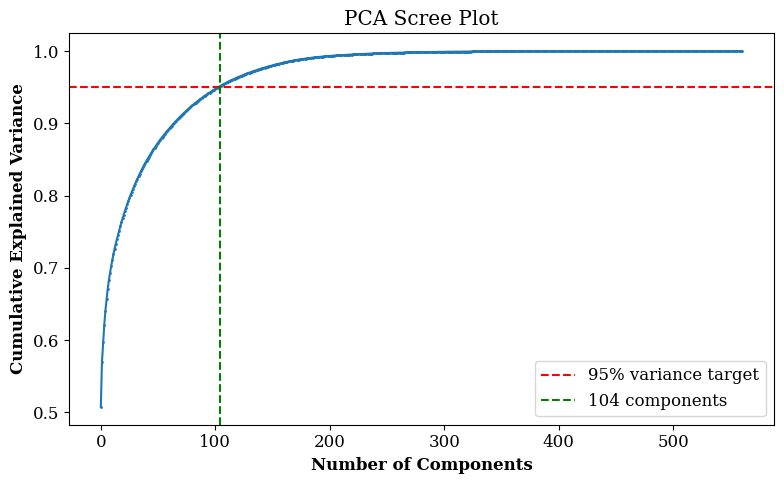

2D PCA explains 56.98% of variance.


In [28]:
pca_full = PCA(random_state=RANDOM_STATE)
pca_full.fit(X_scaled)
cum_var = np.cumsum(pca_full.explained_variance_ratio_)

n_components_95 = np.argmax(cum_var >= 0.95) + 1
print(f"Components needed for 95% variance: {n_components_95}")

fig = plt.figure(figsize=(8, 5))
plt.plot(range(1, len(cum_var) + 1), cum_var, marker='.', markersize=2)
plt.axhline(0.95, color='red', linestyle='--', label='95% variance target')
plt.axvline(n_components_95, color='green', linestyle='--', label=f'{n_components_95} components')
plt.xlabel('Number of Components')
plt.ylabel('Cumulative Explained Variance')
plt.title('PCA Scree Plot')
plt.legend()
plt.tight_layout()
save_eps_figure(fig, 'fig_pca_scree', dpi=600)
plt.close()

# Transform features for clustering
X_pca = pca_full.transform(X_scaled)[:, :n_components_95]
print(f"X_pca shape: {X_pca.shape}")

# 2D PCA projection for visualization
pca_2d = PCA(n_components=2, random_state=RANDOM_STATE)
X_pca_2d = pca_2d.fit_transform(X_scaled)
print(f"Explained variance of 2D PCA projection: {pca_2d.explained_variance_ratio_.sum()*100:.2f}%")


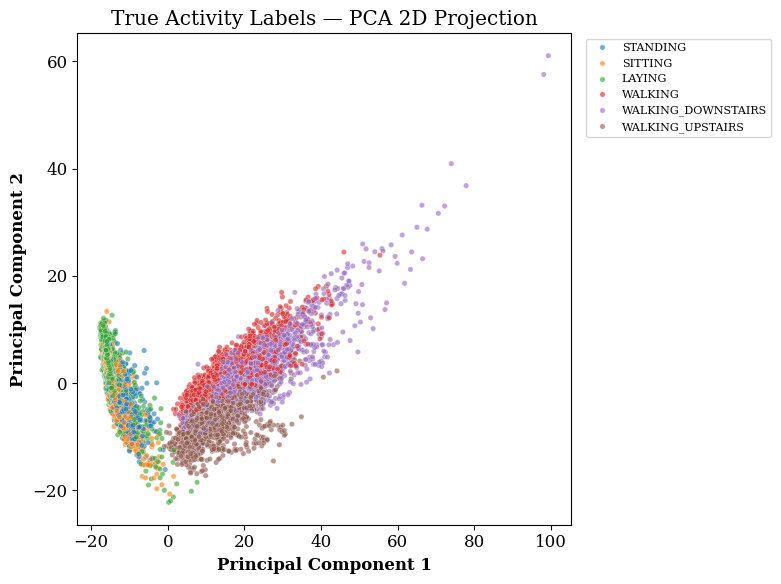

In [29]:
fig = plt.figure(figsize=(8, 6))
sns.scatterplot(x=X_pca_2d[:, 0], y=X_pca_2d[:, 1], hue=y_true, palette='tab10', s=15, alpha=0.7, rasterized=True)
plt.xlabel('Principal Component 1')
plt.ylabel('Principal Component 2')
plt.title('True Activity Labels - PCA 2D Projection')
plt.legend(bbox_to_anchor=(1.02, 1), loc='upper left', fontsize=10)
plt.tight_layout()
save_eps_figure(fig, 'fig_pca_2d', dpi=600)
plt.close()


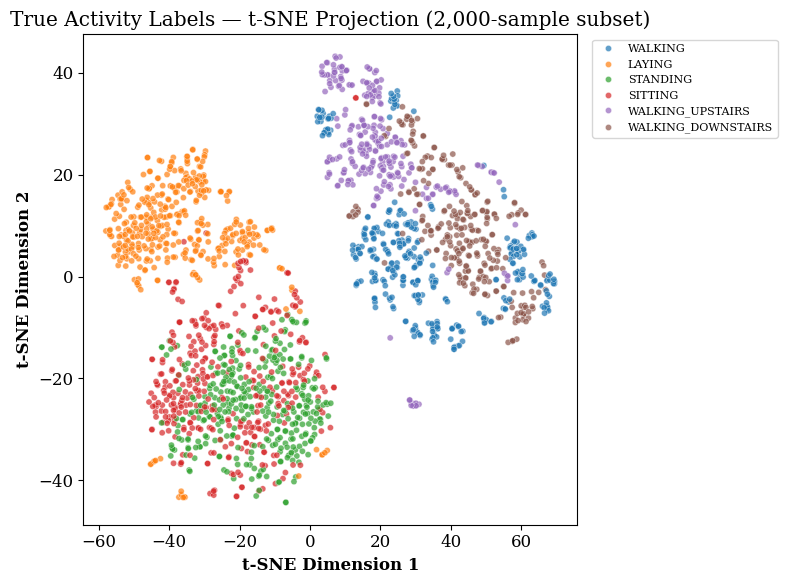

In [30]:
# t-SNE is much slower than PCA, so it's run on a random subsample rather than all ~10,300 rows.
tsne_sample_idx = np.random.RandomState(RANDOM_STATE).choice(len(X_scaled), size=2000, replace=False)
tsne = TSNE(n_components=2, random_state=RANDOM_STATE, perplexity=30, init='pca')
X_tsne = tsne.fit_transform(X_scaled[tsne_sample_idx])

plt.figure(figsize=(8, 6))
sns.scatterplot(x=X_tsne[:, 0], y=X_tsne[:, 1], hue=y_true.iloc[tsne_sample_idx], palette='tab10', s=20, alpha=0.7)
plt.xlabel('t-SNE Dimension 1')
plt.ylabel('t-SNE Dimension 2')
plt.title('True Activity Labels — t-SNE Projection (2,000-sample subset)')
plt.legend(bbox_to_anchor=(1.02, 1), loc='upper left', fontsize=8)
plt.tight_layout()
plt.close()

## 6. K-Means Clustering — Elbow Method

In [31]:
wcss = []
silhouette_scores = []
k_range = range(2, 9)

for k in k_range:
    km = KMeans(n_clusters=k, random_state=RANDOM_STATE, n_init=10)
    labels = km.fit_predict(X_pca)
    wcss.append(km.inertia_)
    # sample_size keeps this fast on ~10,300 points
    sil = silhouette_score(X_pca, labels, sample_size=2000, random_state=RANDOM_STATE)
    silhouette_scores.append(sil)
    print(f"k={k}: WCSS={km.inertia_:.1f}, Silhouette={sil:.4f}")

elbow_df = pd.DataFrame({"k": list(k_range), "WCSS": wcss, "Silhouette Score": silhouette_scores})
display(elbow_df.round(4))

k=2: WCSS=2986708.6, Silhouette=0.4156
k=3: WCSS=2635081.4, Silhouette=0.3297
k=4: WCSS=2495680.6, Silhouette=0.1669
k=5: WCSS=2369135.5, Silhouette=0.1460
k=6: WCSS=2291589.1, Silhouette=0.1191
k=7: WCSS=2234408.8, Silhouette=0.0856
k=8: WCSS=2180422.0, Silhouette=0.0828


,k,WCSS,Silhouette Score
0,2,2.986709e+06,0.4156
1,3,2.635081e+06,0.3297
2,4,2.495681e+06,0.1669
3,5,2.369136e+06,0.1460
4,6,2.291589e+06,0.1191
5,7,2.234409e+06,0.0856
6,8,2.180422e+06,0.0828


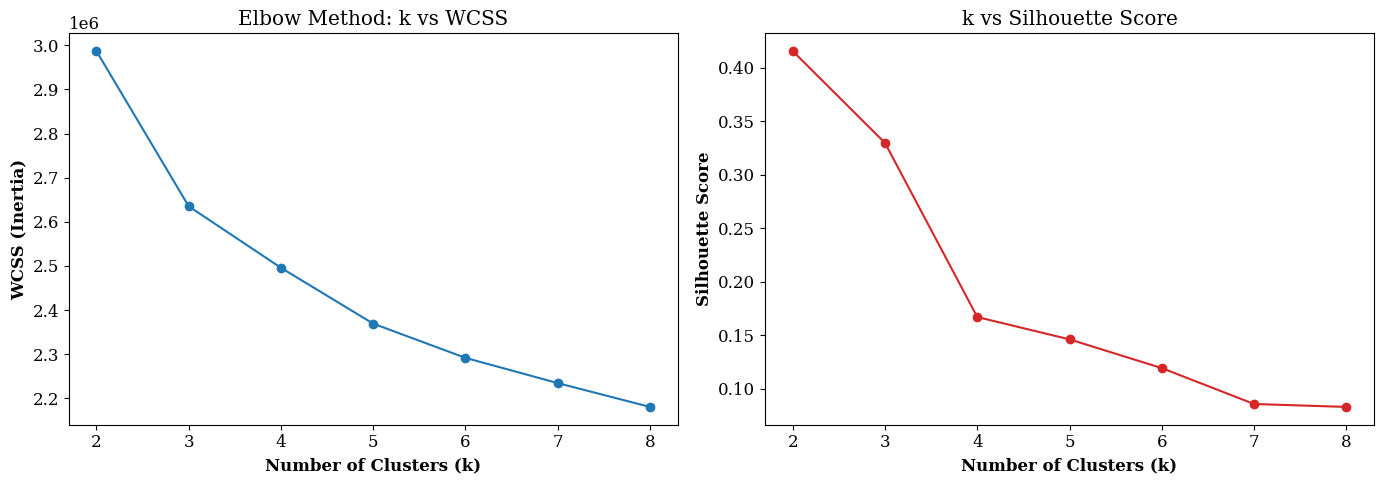

k with the highest silhouette score: 2
There are 6 true activities in this dataset, so k=6 is also worth comparing directly against the silhouette-best k even if they differ.


In [32]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].plot(list(k_range), wcss, marker='o')
axes[0].set_xlabel('Number of Clusters (k)')
axes[0].set_ylabel('WCSS (Inertia)')
axes[0].set_title('Elbow Method: k vs WCSS')

axes[1].plot(list(k_range), silhouette_scores, marker='o', color='#d62728')
axes[1].set_xlabel('Number of Clusters (k)')
axes[1].set_ylabel('Silhouette Score')
axes[1].set_title('k vs Silhouette Score')

plt.tight_layout()
save_eps_figure(fig, 'fig_elbow_silhouette', dpi=600)
plt.close()

best_k = elbow_df.loc[elbow_df["Silhouette Score"].idxmax(), "k"]
print(f"k with the highest silhouette score: {best_k}")


In [33]:
# Common stratified subsample used for the final 3-way comparison (K-Means, DBSCAN, HAC)
SUBSAMPLE_SIZE = 3000
rng = np.random.RandomState(RANDOM_STATE)
sample_idx = (
    pd.Series(np.arange(len(X_pca)))
    .groupby(y_true.values)
    .apply(lambda s: s.sample(frac=SUBSAMPLE_SIZE / len(X_pca), random_state=RANDOM_STATE))
    .values
)

X_sub = X_pca[sample_idx]
y_true_sub = y_true.iloc[sample_idx].reset_index(drop=True)
X_pca_2d_sub = X_pca_2d[sample_idx]

print(f"Common comparison subsample: {X_sub.shape[0]} samples")

K_FINAL = int(best_k)   # change to 6 manually here if you'd rather match the true activity count
kmeans_final = KMeans(n_clusters=K_FINAL, random_state=RANDOM_STATE, n_init=10)
kmeans_labels = kmeans_final.fit_predict(X_sub)
print(f"K-Means fitted with k={K_FINAL}")

Common comparison subsample: 3001 samples
K-Means fitted with k=2


## 7. DBSCAN Clustering

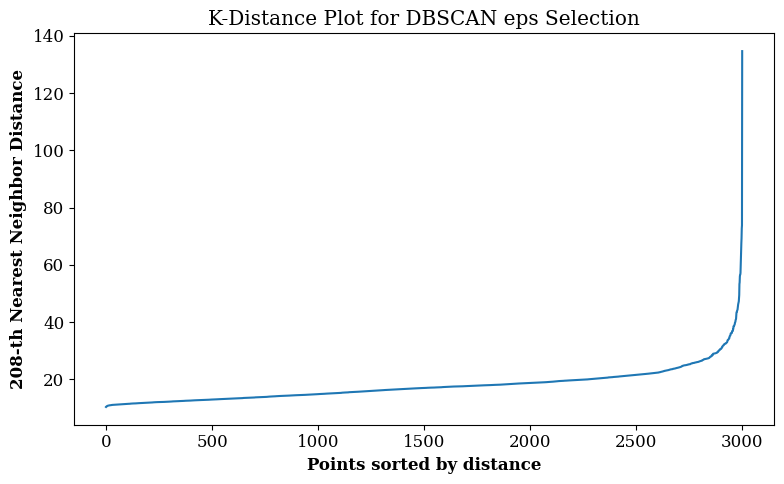

Pick eps at the 'knee' of the curve above (where it starts rising steeply) and set it below.


In [34]:
min_samples = 2 * X_sub.shape[1]   # common rule of thumb: min_samples >= 2 * dimensionality

neighbors = NearestNeighbors(n_neighbors=min_samples)
neighbors_fit = neighbors.fit(X_sub)
distances, _ = neighbors_fit.kneighbors(X_sub)
k_distances = np.sort(distances[:, -1])

fig = plt.figure(figsize=(8, 5))
plt.plot(k_distances)
plt.xlabel('Points sorted by distance')
plt.ylabel(f'{min_samples}-th Nearest Neighbor Distance')
plt.title('K-Distance Plot for DBSCAN eps Selection')
plt.tight_layout()
save_eps_figure(fig, 'fig_kdistance', dpi=600)
plt.close()

print("Pick eps at the 'knee' of the curve above and set it below.")


In [35]:
# Set eps based on where the knee appears in the plot above, then re-run this cell.
eps = float(np.percentile(k_distances, 90))   # starting heuristic — adjust after inspecting the plot
print(f"Using eps = {eps:.4f}, min_samples = {min_samples}")

dbscan = DBSCAN(eps=eps, min_samples=min_samples)
dbscan_labels = dbscan.fit_predict(X_sub)

n_clusters_dbscan = len(set(dbscan_labels)) - (1 if -1 in dbscan_labels else 0)
n_noise = list(dbscan_labels).count(-1)
print(f"Clusters found: {n_clusters_dbscan}")
print(f"Noise points: {n_noise} ({n_noise/len(dbscan_labels)*100:.1f}% of the sample)")

if n_clusters_dbscan < 2:
    print("\nWarning: DBSCAN found fewer than 2 clusters with this eps — try a smaller eps "
          "(move down the k-distance curve) and re-run this cell.")

Using eps = 24.1429, min_samples = 208
Clusters found: 1
Noise points: 89 (3.0% of the sample)



## 8. Hierarchical Agglomerative Clustering

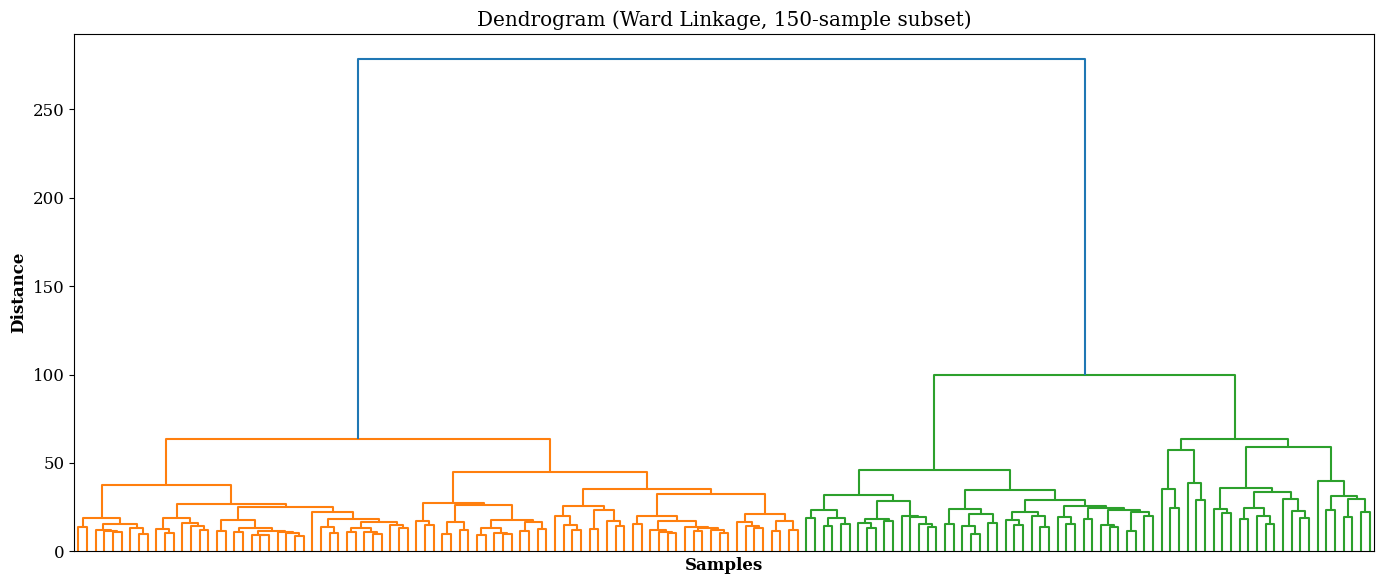

In [36]:
dendro_idx = np.random.RandomState(RANDOM_STATE).choice(len(X_sub), size=150, replace=False)
Z = linkage(X_sub[dendro_idx], method='ward')

fig = plt.figure(figsize=(14, 6))
dendrogram(Z, no_labels=True)
plt.title('Dendrogram (Ward Linkage, 150-sample subset)')
plt.xlabel('Samples')
plt.ylabel('Distance')
plt.tight_layout()
save_eps_figure(fig, 'fig_dendrogram', dpi=600)
plt.close()


In [37]:
hac = AgglomerativeClustering(n_clusters=K_FINAL, linkage='ward')
hac_labels = hac.fit_predict(X_sub)
print(f"Hierarchical clustering fitted with {K_FINAL} clusters (Ward linkage) on the {X_sub.shape[0]}-sample subset.")

Hierarchical clustering fitted with 2 clusters (Ward linkage) on the 3001-sample subset.


## 9. Visualize Clusters (PCA 2D)

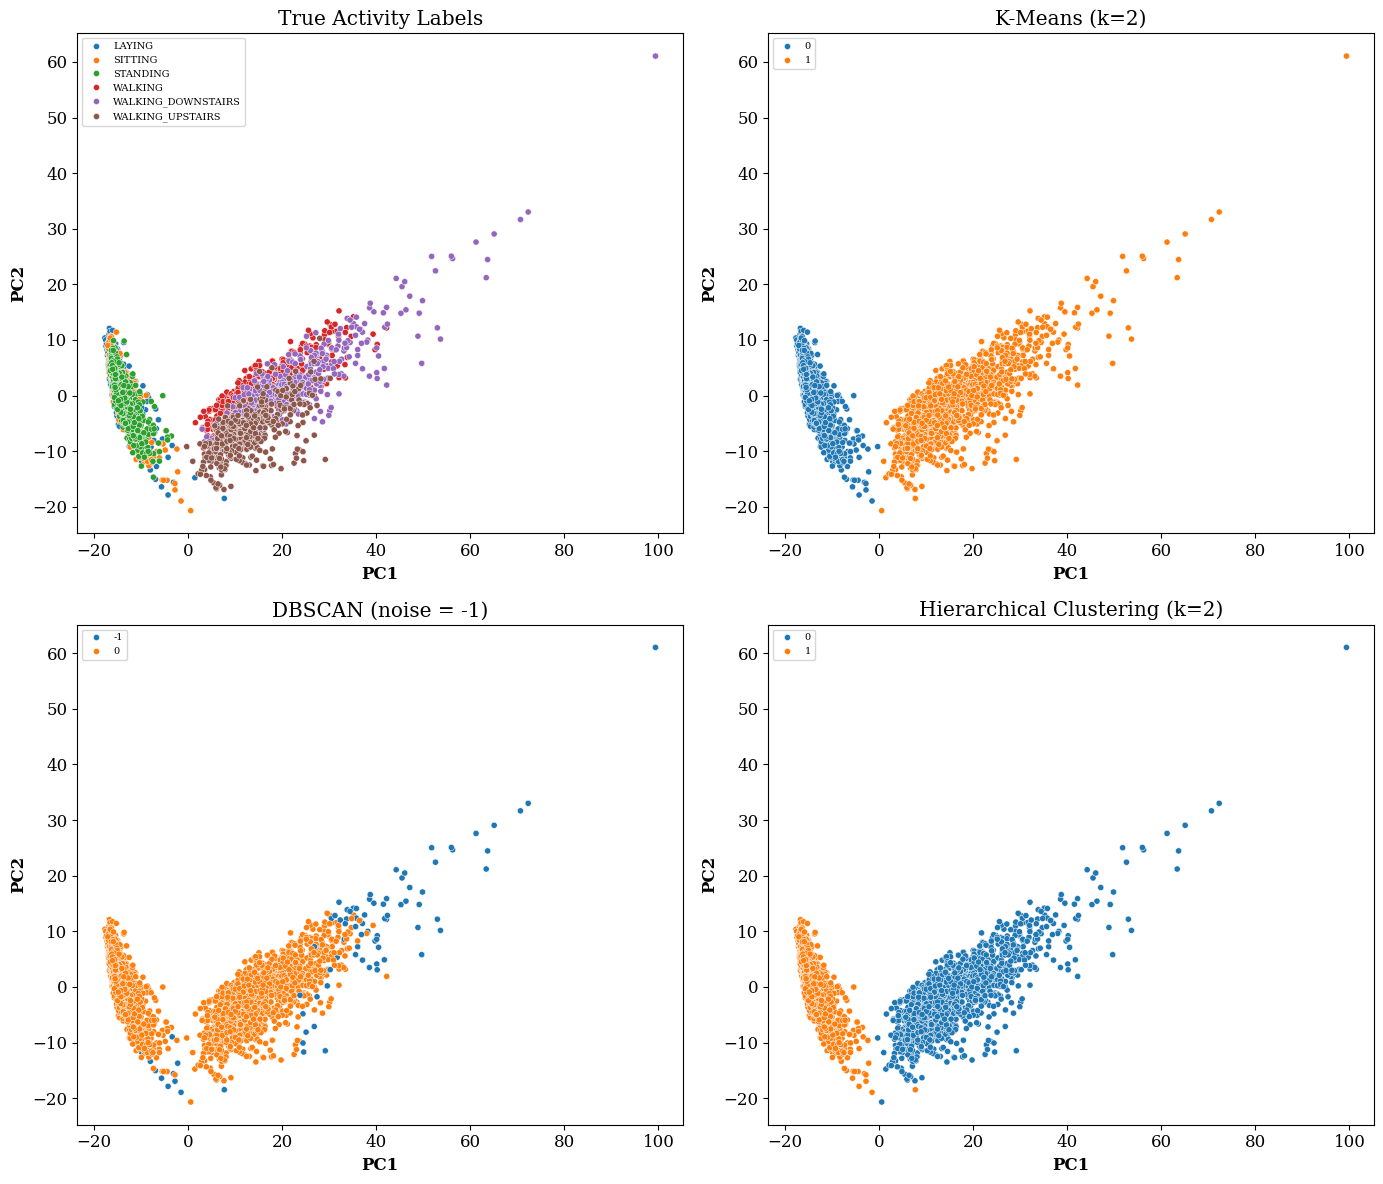

In [38]:
fig, axes = plt.subplots(2, 2, figsize=(14, 12))

sns.scatterplot(x=X_pca_2d_sub[:, 0], y=X_pca_2d_sub[:, 1], hue=y_true_sub, palette='tab10', s=20, ax=axes[0, 0], legend='brief', rasterized=True)
axes[0, 0].set_title('True Activity Labels')

sns.scatterplot(x=X_pca_2d_sub[:, 0], y=X_pca_2d_sub[:, 1], hue=kmeans_labels, palette='tab10', s=20, ax=axes[0, 1], legend='brief', rasterized=True)
axes[0, 1].set_title(f'K-Means (k={K_FINAL})')

sns.scatterplot(x=X_pca_2d_sub[:, 0], y=X_pca_2d_sub[:, 1], hue=dbscan_labels, palette='tab10', s=20, ax=axes[1, 0], legend='brief', rasterized=True)
axes[1, 0].set_title('DBSCAN (noise = -1)')

sns.scatterplot(x=X_pca_2d_sub[:, 0], y=X_pca_2d_sub[:, 1], hue=hac_labels, palette='tab10', s=20, ax=axes[1, 1], legend='brief', rasterized=True)
axes[1, 1].set_title(f'Hierarchical Clustering (k={K_FINAL})')

for ax in axes.flat:
    ax.set_xlabel('PC1')
    ax.set_ylabel('PC2')
    ax.legend(fontsize=8)

plt.tight_layout()
save_eps_figure(fig, 'fig_cluster_scatter', dpi=600)
plt.close()


## 10. Evaluation Metrics

In [39]:
# rules.md Section 4.3 & 4.5 compliant reusable functions for training, evaluation & metrics display
def train_and_evaluate_clustering_models(X_data, y_true_labels, k_clusters=2, min_samples=208, eps=24.14):
    """Reusable function to train and evaluate K-Means, DBSCAN, and Hierarchical Clustering."""
    # K-Means
    km = KMeans(n_clusters=k_clusters, random_state=RANDOM_STATE, n_init=10)
    km_labels = km.fit_predict(X_data)
    
    # DBSCAN
    db = DBSCAN(eps=eps, min_samples=min_samples)
    db_labels = db.fit_predict(X_data)
    
    # Hierarchical Agglomerative Clustering
    hac = AgglomerativeClustering(n_clusters=k_clusters, linkage='ward')
    hac_labels = hac.fit_predict(X_data)
    
    models_labels = {
        "K-Means": km_labels,
        "DBSCAN": db_labels,
        "Hierarchical": hac_labels
    }
    
    results = []
    for name, labels in models_labels.items():
        mask = labels != -1 if -1 in labels else np.ones(len(labels), dtype=bool)
        if mask.sum() > 1 and len(set(labels[mask])) > 1:
            sil = silhouette_score(X_data[mask], labels[mask])
            db_idx = davies_bouldin_score(X_data[mask], labels[mask])
            ch = calinski_harabasz_score(X_data[mask], labels[mask])
        else:
            sil = db_idx = ch = np.nan

        ari = adjusted_rand_score(y_true_labels, labels)
        nmi = normalized_mutual_info_score(y_true_labels, labels)
        results.append([name, sil, db_idx, ch, ari, nmi])

    metrics_df = pd.DataFrame(results, columns=[
        "Algorithm", "Silhouette Score", "Davies-Bouldin Index", "Calinski-Harabasz Index",
        "Adjusted Rand Index", "Normalized Mutual Info"
    ])
    return metrics_df, models_labels

metrics_df, models_labels = train_and_evaluate_clustering_models(X_sub, y_true_sub, k_clusters=K_FINAL, min_samples=min_samples, eps=eps)
display(metrics_df.round(4))


,Algorithm,Silhouette Score,Davies-Bouldin Index,Calinski-Harabasz Index,Adjusted Rand Index,Normalized Mutual Info
0,K-Means,0.4115,1.0199,2491.6289,0.3297,0.5467
1,DBSCAN,NaN,NaN,NaN,0.0037,0.0224
2,Hierarchical,0.4113,1.0205,2485.7824,0.3315,0.5529


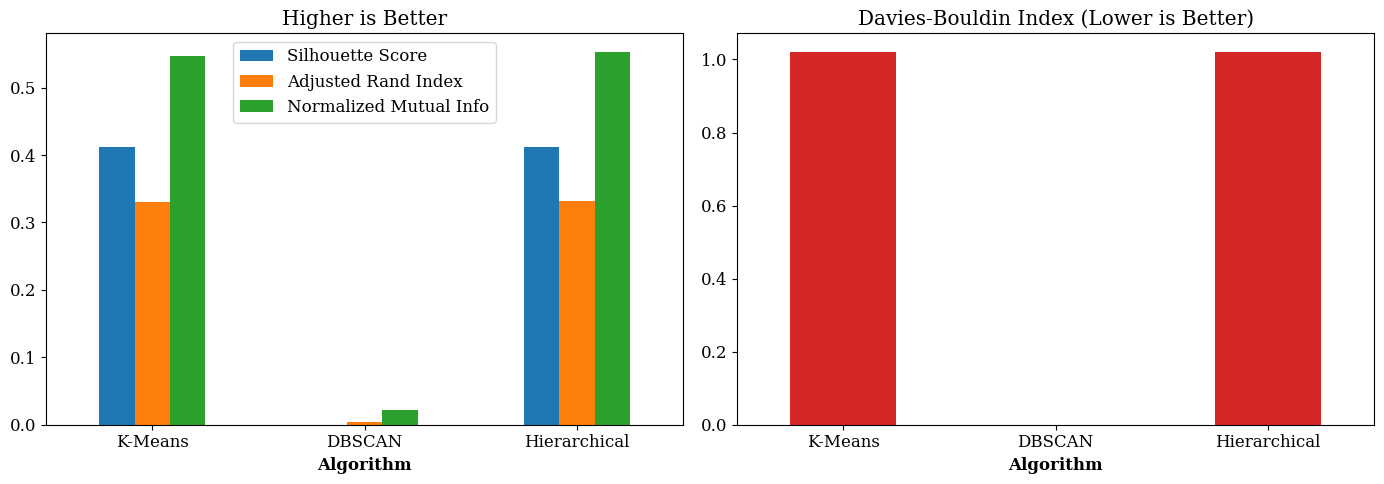

In [40]:
def compute_and_display_clustering_metrics(metrics_df, save_prefix='fig_metrics_comparison'):
    """Reusable function to compute, display and export performance comparison charts."""
    fig, axes = plt.subplots(1, 2, figsize=(14, 5))

    metrics_df.set_index("Algorithm")[["Silhouette Score", "Adjusted Rand Index", "Normalized Mutual Info"]].plot(kind='bar', ax=axes[0])
    axes[0].set_title('Higher is Better Metrics')
    axes[0].tick_params(axis='x', rotation=0)

    metrics_df.set_index("Algorithm")[["Davies-Bouldin Index"]].plot(kind='bar', ax=axes[1], color='#d62728', legend=False)
    axes[1].set_title('Davies-Bouldin Index (Lower is Better)')
    axes[1].tick_params(axis='x', rotation=0)

    plt.tight_layout()
    save_eps_figure(fig, save_prefix, dpi=600)
    plt.close()

compute_and_display_clustering_metrics(metrics_df, save_prefix='fig_metrics_comparison')


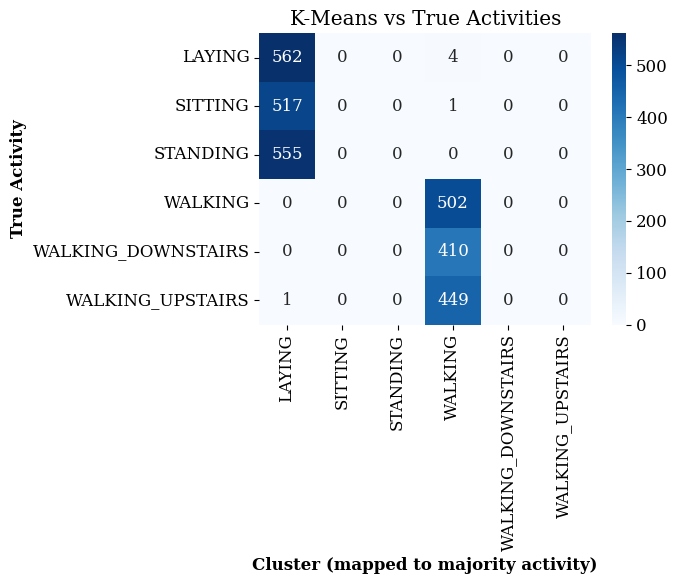

In [41]:
# Optional: confusion matrix between clusters and true activities (by majority-vote mapping)
def cluster_to_activity_confusion(labels, y_true_labels, title):
    mapped = pd.Series(labels).map(
        pd.crosstab(labels, y_true_labels).idxmax(axis=1)
    )
    cm = confusion_matrix(y_true_labels, mapped, labels=y_true_labels.unique())
    plt.figure(figsize=(7, 6))
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
                xticklabels=y_true_labels.unique(), yticklabels=y_true_labels.unique())
    plt.title(title)
    plt.ylabel('True Activity')
    plt.xlabel('Cluster (mapped to majority activity)')
    plt.tight_layout()
    plt.close()

cluster_to_activity_confusion(kmeans_labels, y_true_sub, "K-Means vs True Activities")

## 11. Observations
## Conclusion